# 👁️ AI Fundus Analyser — Diabetic Retinopathy Grading

**One-click notebook:** downloads the data, trains the model, shows the results, and packages everything for the **Raspberry Pi**.

### How to run
1. `Runtime → Change runtime type → T4 GPU` if available. If Colab says *\"Failed to assign a backend\"*, pick **CPU** instead — the notebook detects it and switches to lighter settings automatically.
2. `Runtime → Run all`.
3. At the end a file **`dr_pi_bundle.zip`** downloads automatically. Copy it to the Pi.

**On Kaggle instead:** Settings panel → Accelerator **GPU T4 x2** and **Internet ON** (needs a phone-verified account) → Run All → get the zip from the Output panel.

### What it does
| Step | Detail |
|---|---|
| Data | APTOS 2019 (Aravind Eye Hospital, India) — 3,662 graded fundus images, pulled automatically from Hugging Face (no Kaggle key needed) |
| Preprocessing | Black-border crop → square → resize → Ben Graham lighting normalisation → circular mask |
| Model | EfficientNet-B0 (ImageNet pre-trained), **regression head** + tuned thresholds → ICDR grade 0–4 |
| Metrics | Quadratic Weighted Kappa (QWK), accuracy, confusion matrix, **referable DR (grade ≥ 2) sensitivity / specificity / AUC** |
| Explainability | Grad-CAM heat-maps |
| Pi export | ONNX FP32 + INT8 (ONNX Runtime), `pi_inference.py`, `config.json`, image-quality check |

Grades: **0** No DR · **1** Mild · **2** Moderate · **3** Severe · **4** Proliferative DR

> ⚠️ Research / prototype screening aid only — **not a medical diagnosis**. Clinical use needs validation against ophthalmologist grading on images from your own camera, and regulatory approval (CDSCO in India).

In [ ]:
#@title ⚙️ 1. Settings (the only cell you might want to edit)
import os
DATA_MODE = "full"        # "full"  = original hi-res APTOS 2019 (~9 GB download, best accuracy, ~45-60 min total on T4)
                          # "quick" = 224x224 copy of APTOS (small download, fast test run, lower accuracy)
MODEL_NAME = "efficientnet_b0"   # Pi-friendly. "efficientnet_b2" = a bit more accurate, ~2x slower on the Pi
EPOCHS = 20
BATCH_SIZE = 32
LR = 3e-4
SEED = 42
SAVE_TO_DRIVE = False     # True = also copy the bundle to Google Drive (asks permission once)
RUN_UPLOAD_DEMO = False   # True = at the end, upload your own fundus photo and get a prediction

IMG_SIZE = 384 if DATA_MODE == "full" else 224
ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working/dr_project" if ON_KAGGLE else "/content/dr_project"
EXPORT = f"{WORK}/export"
print(f"Mode: {DATA_MODE} | model: {MODEL_NAME} | image size: {IMG_SIZE} | epochs: {EPOCHS}")

Mode: full | model: efficientnet_b0 | image size: 384 | epochs: 20


In [ ]:
#@title 📦 2. Install & import
!pip -q install timm onnx onnxruntime onnxscript datasets

import os, json, time, random, shutil, copy, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (cohen_kappa_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, accuracy_score)
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("⚠️  No GPU available — switching to CPU-friendly settings (quick 224px data, 6 epochs, ~1-1.5 h).")
    print("    For best accuracy, re-run later with Runtime → Change runtime type → T4 GPU.")
    DATA_MODE, IMG_SIZE, EPOCHS, BATCH_SIZE = "quick", 224, min(EPOCHS, 6), 16
else:
    print("✅ GPU:", torch.cuda.get_device_name(0))

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

os.makedirs(WORK, exist_ok=True)
os.makedirs(EXPORT, exist_ok=True)
GRADES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
print("torch", torch.__version__, "| timm", timm.__version__)

✅ GPU: Tesla T4
torch 2.11.0+cu130 | timm 1.0.30


In [ ]:
#@title 🧪 3. Fundus preprocessing (identical code is copied into the Pi script)
PREPROC_CODE = r'''
import cv2
import numpy as np

def crop_fundus(img_rgb, tol=7):
    """Remove the black border around the circular fundus."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if mask.sum() < 0.05 * mask.size:      # almost entirely dark: leave unchanged
        return img_rgb
    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]
    return img_rgb[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]

def pad_to_square(img):
    h, w = img.shape[:2]
    s = max(h, w)
    out = np.zeros((s, s, 3), dtype=img.dtype)
    y, x = (s - h) // 2, (s - w) // 2
    out[y:y + h, x:x + w] = img
    return out

def preprocess_fundus(img_rgb, size=384, ben_graham=True):
    """RGB uint8 image in -> RGB uint8 (size x size) out. Used for training AND on the Pi."""
    img = pad_to_square(crop_fundus(img_rgb))
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    if ben_graham:   # local contrast / lighting normalisation (Ben Graham, Kaggle DR 2015)
        blur = cv2.GaussianBlur(img, (0, 0), sigmaX=size / 30)
        img = cv2.addWeighted(img, 4, blur, -4, 128)
    mask = np.zeros((size, size), np.uint8)
    cv2.circle(mask, (size // 2, size // 2), int(size * 0.47), 1, -1)
    img = img * mask[:, :, None] + 128 * (1 - mask[:, :, None])
    return img.astype(np.uint8)

def quality_metrics(img_rgb):
    """Simple image-quality numbers: brightness and sharpness of the fundus (green channel)."""
    img = pad_to_square(crop_fundus(img_rgb))
    img = cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA)
    g = img[:, :, 1]
    mask = np.zeros((512, 512), np.uint8)
    cv2.circle(mask, (256, 256), 230, 1, -1)
    inside = mask == 1
    lap = cv2.Laplacian(g, cv2.CV_64F)
    return {"brightness": float(g[inside].mean()), "sharpness": float(lap[inside].var())}
'''
exec(PREPROC_CODE)
print("Preprocessing functions ready.")

Preprocessing functions ready.


README.md:   0%|          | 0.00/520 [00:00<?, ?B/s]

data/train-00000-of-00013-b6971806b485b3(…): reconstructing file:   0%|          |  0.00B /  516MB            

data/train-00000-of-00013-b6971806b485b3(…): downloading bytes:           |  0.00B            

data/train-00001-of-00013-3ef9284bda48b8(…): reconstructing file:   0%|          |  0.00B /  482MB            

data/train-00001-of-00013-3ef9284bda48b8(…): downloading bytes:           |  0.00B            

data/train-00002-of-00013-3007d5f3a80d01(…): reconstructing file:   0%|          |  0.00B /  446MB            

... (20 outputs left out)

data/train-00012-of-00013-2fde0e05e0019c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3662 [00:00<?, ? examples/s]

Preprocessing:   0%|          | 0/3662 [00:00<?, ?it/s]


Images: 3662
  0 No DR              1805  (49.3%)
  1 Mild                370  (10.1%)
  2 Moderate            999  (27.3%)
  3 Severe              193  (5.3%)
  4 Proliferative DR    295  (8.1%)


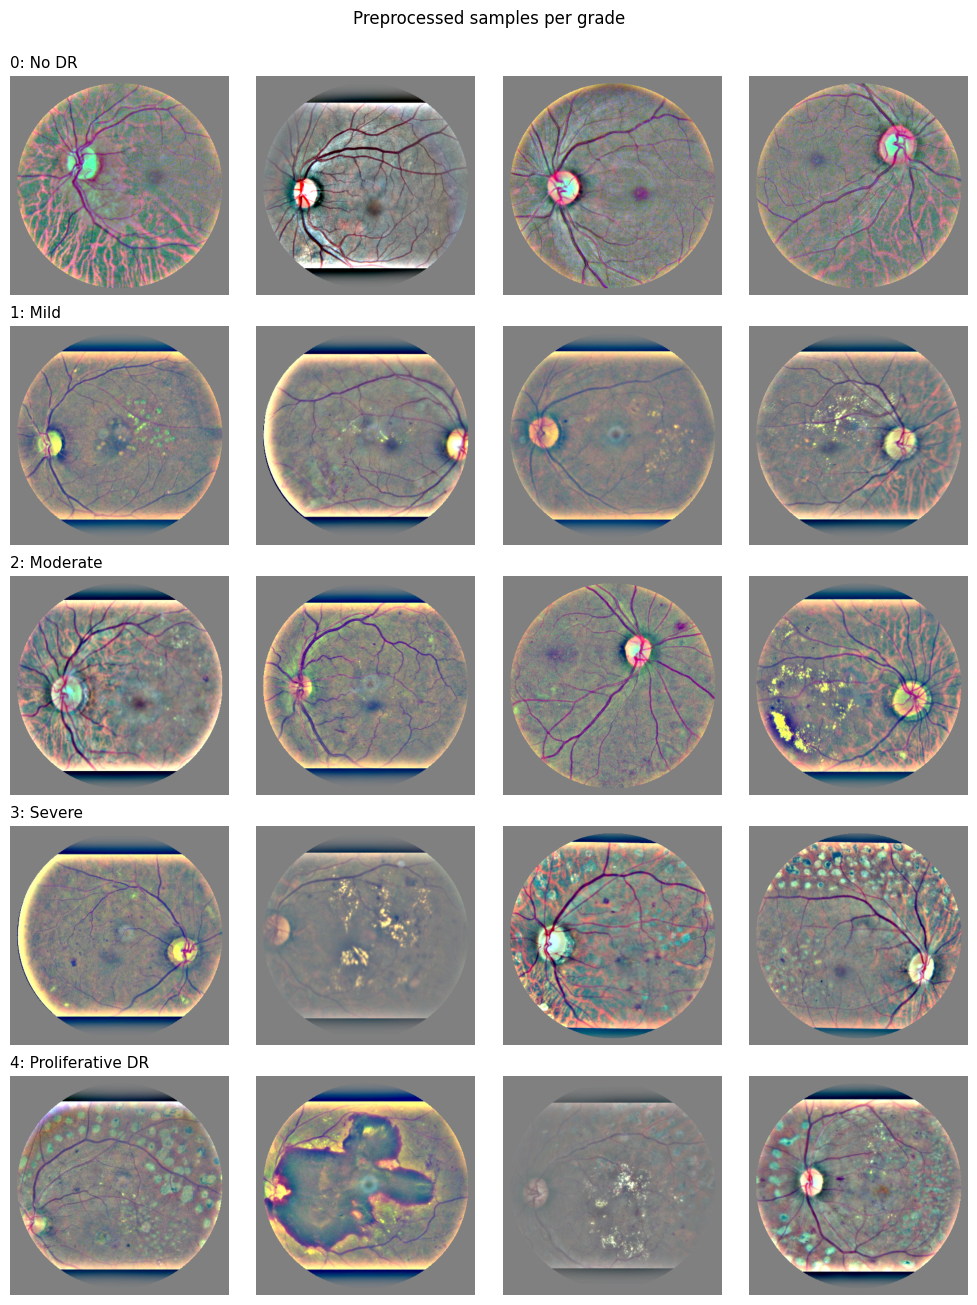

Image-quality thresholds: {'sharpness_min': 9.628463123987338, 'brightness_min': 27.827681262747504, 'brightness_max': 114.16378878400087}


In [ ]:
#@title ⬇️ 4. Download APTOS 2019 + preprocess (cached, runs once)
# CELL:DATA
from datasets import load_dataset, Image as HFImage

PREP_DIR = f"{WORK}/prep_{DATA_MODE}_{IMG_SIZE}"
META_CSV = f"{PREP_DIR}/meta.csv"
os.makedirs(PREP_DIR, exist_ok=True)

def _prep_one(job):
    idx, img_bytes, img_path, label, out_path, size = job
    if img_bytes is not None:
        bgr = cv2.imdecode(np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR)
    else:
        bgr = cv2.imread(img_path)
    if bgr is None:
        return None
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    q = quality_metrics(rgb)
    out = preprocess_fundus(rgb, size)
    cv2.imwrite(out_path, cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 1])
    return dict(idx=idx, path=out_path, label=int(label), **q)

if os.path.exists(META_CSV):
    df = pd.read_csv(META_CSV)
    print(f"Using cached preprocessed images: {len(df)}")
else:
    repo = "sngsfydy/aptos" if DATA_MODE == "full" else "bumbledeep/aptos"
    print(f"Downloading {repo} from Hugging Face ... (full mode ≈ 9 GB, takes a few minutes)")
    ds = load_dataset(repo, split="train")
    label_col = "label_code" if "label_code" in ds.column_names else "label"
    ds = ds.cast_column("image", HFImage(decode=False))
    n = len(ds)
    rows, CHUNK = [], 64
    with ThreadPoolExecutor(max_workers=(os.cpu_count() or 2) + 2) as ex, tqdm(total=n, desc="Preprocessing") as bar:
        for start in range(0, n, CHUNK):
            jobs = []
            for i in range(start, min(start + CHUNK, n)):
                r = ds[i]
                jobs.append((i, r["image"].get("bytes"), r["image"].get("path"), r[label_col],
                             f"{PREP_DIR}/{i:05d}.png", IMG_SIZE))
            for res in ex.map(_prep_one, jobs):
                if res is not None:
                    rows.append(res)
            bar.update(len(jobs))
    df = pd.DataFrame(rows)
    df.to_csv(META_CSV, index=False)
    del ds

print(f"\nImages: {len(df)}")
counts = df.label.value_counts().sort_index()
for g, c in counts.items():
    print(f"  {g} {GRADES[g]:<17} {c:5d}  ({100 * c / len(df):.1f}%)")

fig, axes = plt.subplots(5, 4, figsize=(10, 13))
for g in range(5):
    sub = df[df.label == g]
    picks = sub.sample(min(4, len(sub)), random_state=SEED) if len(sub) else sub
    for j in range(4):
        ax = axes[g, j]; ax.axis("off")
        if j < len(picks):
            ax.imshow(cv2.cvtColor(cv2.imread(picks.iloc[j].path), cv2.COLOR_BGR2RGB))
            if j == 0: ax.set_title(f"{g}: {GRADES[g]}", loc="left", fontsize=11)
plt.suptitle("Preprocessed samples per grade", y=1.0); plt.tight_layout(); plt.show()

# Quality thresholds learned from the (good-quality) training data — a starting point for your camera
QUALITY = {
    "sharpness_min": float(df.sharpness.quantile(0.01)),
    "brightness_min": float(df.brightness.quantile(0.005)),
    "brightness_max": float(df.brightness.quantile(0.995)),
}
print("Image-quality thresholds:", QUALITY)

In [ ]:
#@title ✂️ 5. Train / validation / test split (70 / 15 / 15, stratified)
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

train_tf = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(180, fill=128),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
    T.RandomApply([T.GaussianBlur(3)], p=0.2),
    T.ToTensor(), T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

class FundusDS(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame.path.values
        self.y = frame.label.values.astype(np.float32)
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        return self.tf(img), torch.tensor(self.y[i])

NW = min(4, os.cpu_count() or 2)
train_dl = DataLoader(FundusDS(train_df, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=NW, pin_memory=True, drop_last=True)
val_dl = DataLoader(FundusDS(val_df, eval_tf), batch_size=BATCH_SIZE, num_workers=NW, pin_memory=True)
test_dl = DataLoader(FundusDS(test_df, eval_tf), batch_size=BATCH_SIZE, num_workers=NW, pin_memory=True)

train 2563 | val 549 | test 550


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/20:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch  1 | train loss 3.8505 | val loss 1.9815 | val QWK 0.2592 | val acc 0.355 | 96s  ⭐ saved


Epoch 2/20:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch  2 | train loss 2.2857 | val loss 1.2275 | val QWK 0.2138 | val acc 0.366 | 67s


... (42 outputs left out)

Epoch 19 | train loss 0.1859 | val loss 0.1947 | val QWK 0.8137 | val acc 0.698 | 62s


Epoch 20/20:   0%|          | 0/80 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c03c65b8220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c03c65b8220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 20 | train loss 0.1882 | val loss 0.1986 | val QWK 0.8181 | val acc 0.712 | 64s

Best validation QWK: 0.8189


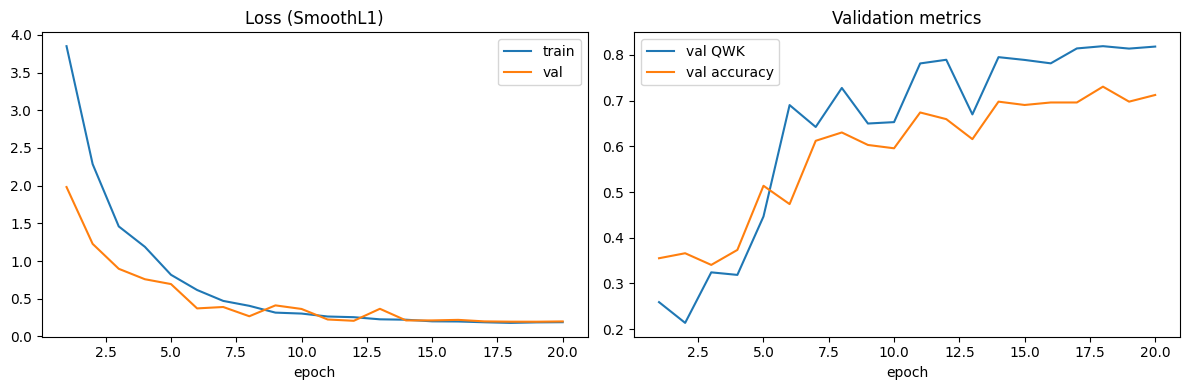

In [ ]:
#@title 🏋️ 6. Train
DEFAULT_THR = [0.5, 1.5, 2.5, 3.5]
def to_grade(pred, thr=DEFAULT_THR):
    return np.digitize(pred, thr)
def qwk(y, g):
    return cohen_kappa_score(y, g, weights="quadratic")

model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=1, drop_rate=0.3).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_dl), pct_start=0.1)
criterion = nn.SmoothL1Loss()
USE_AMP = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
BEST_PT = f"{EXPORT}/best_model.pt"

def predict(net, loader):
    net.eval(); out = []
    with torch.no_grad(), torch.autocast(device_type=DEVICE, enabled=USE_AMP):
        for x, _ in loader:
            out.append(net(x.to(DEVICE)).float().squeeze(1).cpu().numpy())
    return np.concatenate(out)

history, best_qwk = [], -1.0
y_val = val_df.label.values
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tot, n = 0.0, 0
    for x, y in tqdm(train_dl, leave=False, desc=f"Epoch {ep}/{EPOCHS}"):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            out = model(x).squeeze(1).float()
        loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(x); n += len(x)
    vp = predict(model, val_dl)
    vloss = criterion(torch.tensor(vp), torch.tensor(y_val, dtype=torch.float32)).item()
    vq = qwk(y_val, to_grade(vp))
    vacc = accuracy_score(y_val, to_grade(vp))
    history.append(dict(epoch=ep, train_loss=tot / n, val_loss=vloss, val_qwk=vq, val_acc=vacc))
    flag = ""
    if vq > best_qwk:
        best_qwk = vq; torch.save(model.state_dict(), BEST_PT); flag = "  ⭐ saved"
    print(f"Epoch {ep:2d} | train loss {tot / n:.4f} | val loss {vloss:.4f} | val QWK {vq:.4f} | val acc {vacc:.3f} | {time.time() - t0:.0f}s{flag}")

model.load_state_dict(torch.load(BEST_PT, map_location=DEVICE))
print(f"\nBest validation QWK: {best_qwk:.4f}")

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("Loss (SmoothL1)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_qwk, label="val QWK"); ax[1].plot(h.epoch, h.val_acc, label="val accuracy")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{EXPORT}/training_curves.png", dpi=120); plt.show()

Tuned thresholds: [0.58, 1.08, 1.88, 2.72]  (val QWK 0.8189 → 0.8765)

===== TEST SET (550 images never seen in training) =====
QWK (default thresholds): 0.8352
QWK (tuned thresholds)  : 0.8773
Accuracy (5-class)      : 0.6982

                  precision    recall  f1-score   support

           No DR      0.965     0.923     0.943       271
            Mild      0.404     0.375     0.389        56
        Moderate      0.713     0.547     0.619       150
          Severe      0.148     0.448     0.222        29
Proliferative DR      0.500     0.409     0.450        44

        accuracy                          0.698       550
       macro avg      0.546     0.540     0.525       550
    weighted avg      0.759     0.698     0.721       550

===== REFERABLE DR (grade ≥ 2) =====
Sensitivity: 0.937   Specificity: 0.908   AUC: 0.973   (TP 209, FN 14, TN 297, FP 30)


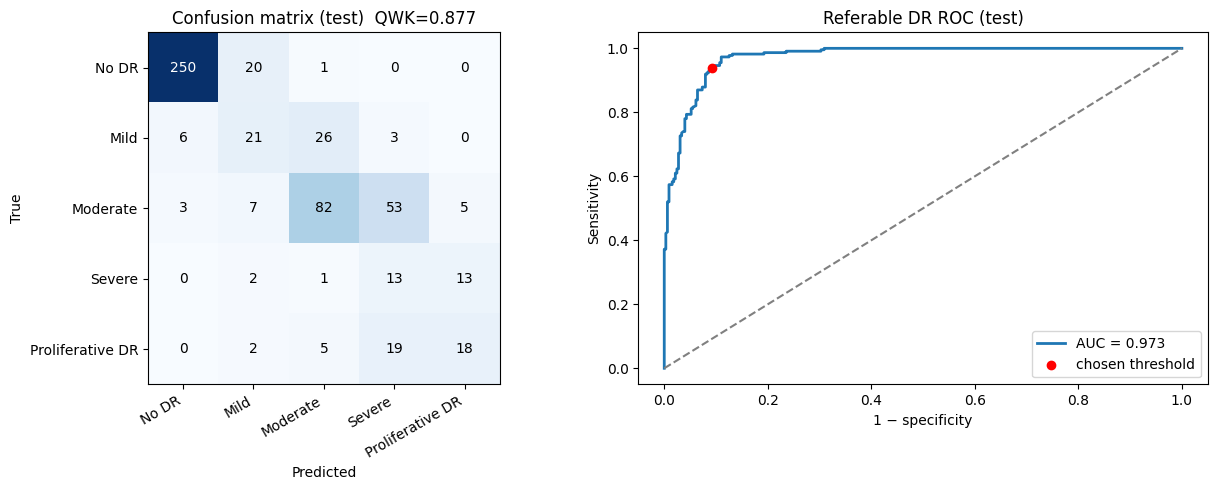

In [ ]:
#@title 📊 7. Tune grade thresholds on validation, evaluate on the held-out TEST set
def optimize_thresholds(pred, y, init=DEFAULT_THR, rounds=3):
    thr = list(init); best = qwk(y, to_grade(pred, thr))
    for _ in range(rounds):
        for i in range(4):
            lo = thr[i - 1] + 0.02 if i > 0 else 0.0
            hi = thr[i + 1] - 0.02 if i < 3 else 4.5
            for c in np.arange(lo, hi, 0.02):
                trial = thr.copy(); trial[i] = float(c)
                s = qwk(y, to_grade(pred, trial))
                if s > best:
                    best, thr = s, trial
    return [round(t, 3) for t in thr], best

val_pred = predict(model, val_dl)
THRESHOLDS, val_qwk_opt = optimize_thresholds(val_pred, y_val)
print(f"Tuned thresholds: {THRESHOLDS}  (val QWK {qwk(y_val, to_grade(val_pred)):.4f} → {val_qwk_opt:.4f})")

y_test = test_df.label.values
test_pred = predict(model, test_dl)
g_test = to_grade(test_pred, THRESHOLDS)
TEST_QWK = qwk(y_test, g_test)
TEST_ACC = accuracy_score(y_test, g_test)
print(f"\n===== TEST SET ({len(y_test)} images never seen in training) =====")
print(f"QWK (default thresholds): {qwk(y_test, to_grade(test_pred)):.4f}")
print(f"QWK (tuned thresholds)  : {TEST_QWK:.4f}")
print(f"Accuracy (5-class)      : {TEST_ACC:.4f}\n")
print(classification_report(y_test, g_test, labels=list(range(5)), target_names=GRADES, digits=3, zero_division=0))

# Referable DR = grade >= 2 (moderate or worse) -> refer to ophthalmologist
ref_true = (y_test >= 2).astype(int)
ref_pred = (g_test >= 2).astype(int)
tp = int(((ref_pred == 1) & (ref_true == 1)).sum()); tn = int(((ref_pred == 0) & (ref_true == 0)).sum())
fp = int(((ref_pred == 1) & (ref_true == 0)).sum()); fn = int(((ref_pred == 0) & (ref_true == 1)).sum())
SENS = tp / max(tp + fn, 1); SPEC = tn / max(tn + fp, 1)
AUC = roc_auc_score(ref_true, test_pred) if len(set(ref_true)) == 2 else float("nan")
print("===== REFERABLE DR (grade ≥ 2) =====")
print(f"Sensitivity: {SENS:.3f}   Specificity: {SPEC:.3f}   AUC: {AUC:.3f}   (TP {tp}, FN {fn}, TN {tn}, FP {fp})")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test, g_test, labels=list(range(5)))
im = ax[0].imshow(cm, cmap="Blues")
for i in range(5):
    for j in range(5):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks(range(5)); ax[0].set_yticks(range(5))
ax[0].set_xticklabels(GRADES, rotation=30, ha="right"); ax[0].set_yticklabels(GRADES)
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True"); ax[0].set_title(f"Confusion matrix (test)  QWK={TEST_QWK:.3f}")
if len(set(ref_true)) == 2:
    fpr, tpr, _ = roc_curve(ref_true, test_pred)
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {AUC:.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].scatter([1 - SPEC], [SENS], color="red", zorder=5, label="chosen threshold")
ax[1].set_xlabel("1 − specificity"); ax[1].set_ylabel("Sensitivity"); ax[1].set_title("Referable DR ROC (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{EXPORT}/test_results.png", dpi=120); plt.show()

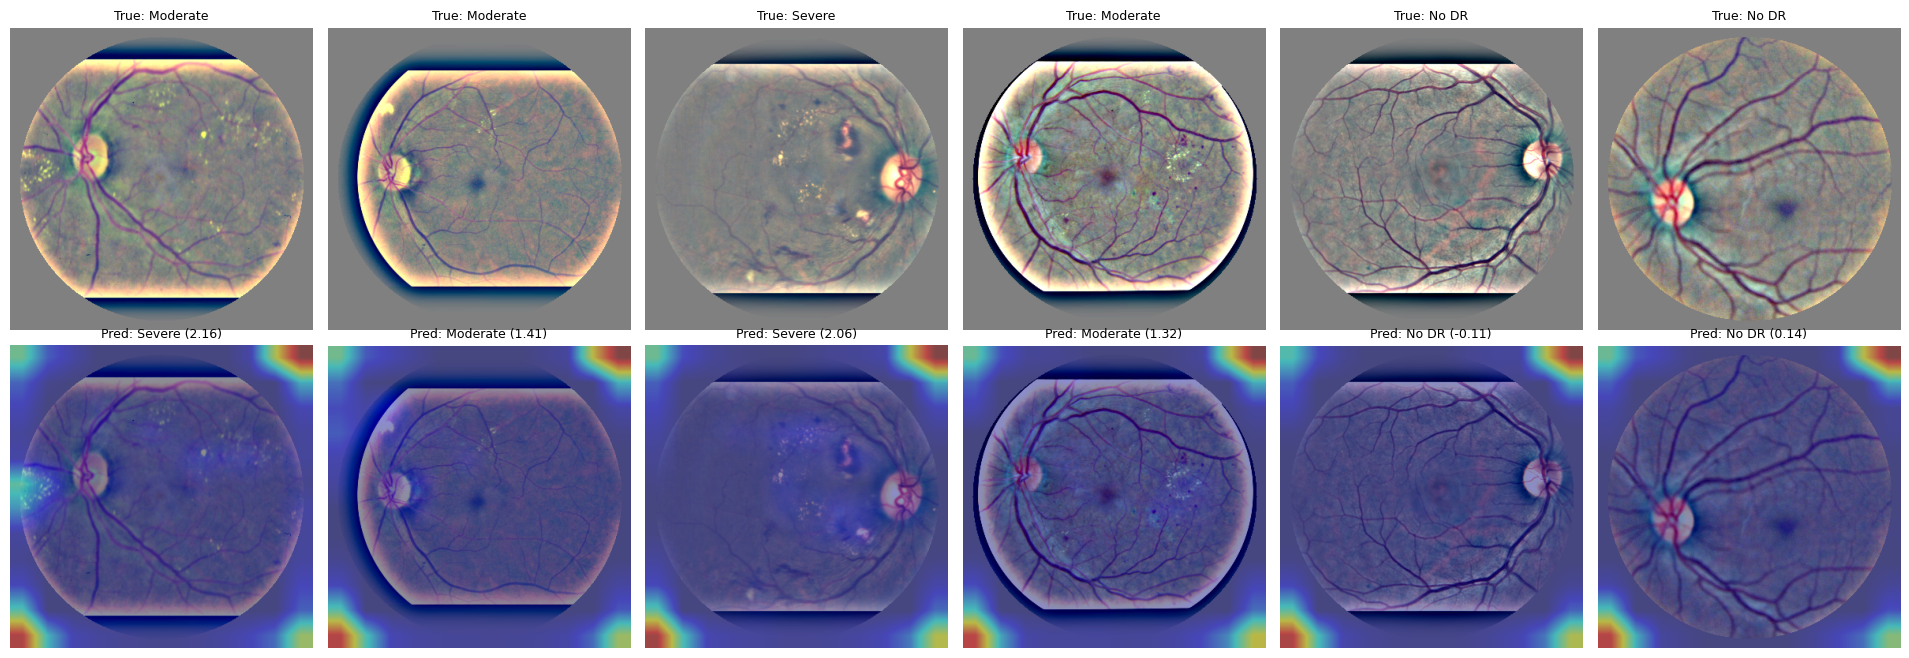

In [ ]:
#@title 🔥 8. Grad-CAM — where is the model looking?
def grad_cam(net, x):
    net.eval(); net.zero_grad(set_to_none=True)
    feats = net.forward_features(x.to(DEVICE))
    feats.retain_grad()
    score = net.forward_head(feats)
    score.sum().backward()
    w = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats).sum(1)).detach()
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
    net.zero_grad(set_to_none=True)
    return score.detach().float().squeeze(1).cpu().numpy(), cam.cpu().numpy()

sev = test_df[test_df.label >= 2]
show = pd.concat([sev.sample(min(4, len(sev)), random_state=SEED),
                  test_df[test_df.label < 2].sample(min(2, int((test_df.label < 2).sum())), random_state=SEED)])
ds_show = FundusDS(show, eval_tf)
xs = torch.stack([ds_show[i][0] for i in range(len(ds_show))])
scores, cams = grad_cam(model, xs)

fig, axes = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6), squeeze=False)
for k in range(len(show)):
    img = cv2.cvtColor(cv2.imread(show.iloc[k].path), cv2.COLOR_BGR2RGB)
    heat = cv2.resize(cams[k], (img.shape[1], img.shape[0]))
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    overlay = (0.55 * img + 0.45 * heat).astype(np.uint8)
    pg = int(to_grade(scores[k:k + 1], THRESHOLDS)[0])
    axes[0, k].imshow(img); axes[0, k].set_title(f"True: {GRADES[show.iloc[k].label]}", fontsize=9)
    axes[1, k].imshow(overlay); axes[1, k].set_title(f"Pred: {GRADES[pg]} ({scores[k]:.2f})", fontsize=9)
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.tight_layout(); plt.savefig(f"{EXPORT}/gradcam.png", dpi=120); plt.show()

In [ ]:
#@title 🍓 9. Export for Raspberry Pi (ONNX FP32 + INT8) and verify
import onnx
import onnxruntime as ort

class DeployWrapper(nn.Module):
    """Input: float32 RGB image in [0,1], shape (1,3,H,W). Output: severity score (1,1). Normalisation is built in."""
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(STD).view(1, 3, 1, 1))
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

deploy = DeployWrapper(copy.deepcopy(model).cpu().float()).eval()
dummy = torch.rand(1, 3, IMG_SIZE, IMG_SIZE)
FP32_PATH = f"{EXPORT}/dr_model_fp32.onnx"
INT8_PATH = f"{EXPORT}/dr_model_int8.onnx"

def export_onnx(module, x, path):
    kw = dict(input_names=["image"], output_names=["score"])
    try:
        torch.onnx.export(module, (x,), path, opset_version=17, dynamo=False, **kw)
    except Exception as e:
        print("Classic exporter unavailable, using dynamo exporter:", type(e).__name__)
        torch.onnx.export(module, (x,), path, dynamo=True, **kw)
    m = onnx.load(path)                       # merge any external weights into one file
    onnx.checker.check_model(m)
    onnx.save_model(m, path, save_as_external_data=False)
    if os.path.exists(path + ".data"):
        os.remove(path + ".data")

export_onnx(deploy, dummy, FP32_PATH)
print(f"FP32 ONNX: {os.path.getsize(FP32_PATH) / 1e6:.1f} MB")

def load_for_onnx(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return (img.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]

def onnx_scores(model_path, paths):
    sess = ort.InferenceSession(model_path, providers=["CPUExecutionProvider"])
    name = sess.get_inputs()[0].name
    return np.array([float(sess.run(None, {name: load_for_onnx(p)})[0].reshape(-1)[0]) for p in tqdm(paths, leave=False)])

# parity check PyTorch vs ONNX
chk = test_df.path.values[:8]
with torch.no_grad():
    t_out = np.array([float(deploy(torch.from_numpy(load_for_onnx(p)))) for p in chk])
o_out = onnx_scores(FP32_PATH, chk)
print(f"PyTorch vs ONNX max difference: {np.abs(t_out - o_out).max():.6f}")

fp32_scores = onnx_scores(FP32_PATH, test_df.path.values)
FP32_QWK = qwk(y_test, to_grade(fp32_scores, THRESHOLDS))
print(f"ONNX FP32 test QWK: {FP32_QWK:.4f}")

# INT8 static quantisation (smaller + faster on the Pi's ARM CPU)
RECOMMENDED = os.path.basename(FP32_PATH)
INT8_QWK = None
try:
    from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat, QuantType
    from onnxruntime.quantization.shape_inference import quant_pre_process

    class CalibReader(CalibrationDataReader):
        def __init__(self, paths, name):
            self.it = iter([{name: load_for_onnx(p)} for p in paths])
        def get_next(self):
            return next(self.it, None)

    pre_path = f"{WORK}/dr_model_pre.onnx"
    quant_pre_process(FP32_PATH, pre_path, skip_symbolic_shape=True)
    calib_paths = val_df.sample(min(200, len(val_df)), random_state=SEED).path.values
    in_name = ort.InferenceSession(FP32_PATH, providers=["CPUExecutionProvider"]).get_inputs()[0].name
    quantize_static(pre_path, INT8_PATH, CalibReader(calib_paths, in_name),
                    quant_format=QuantFormat.QDQ, per_channel=True,
                    activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
    int8_scores = onnx_scores(INT8_PATH, test_df.path.values)
    INT8_QWK = qwk(y_test, to_grade(int8_scores, THRESHOLDS))
    print(f"INT8 ONNX: {os.path.getsize(INT8_PATH) / 1e6:.1f} MB | test QWK: {INT8_QWK:.4f}")
    if INT8_QWK >= FP32_QWK - 0.01:
        RECOMMENDED = os.path.basename(INT8_PATH)
except Exception as e:
    print("INT8 quantisation skipped:", e)
print("➡️  Model the Pi will use by default:", RECOMMENDED)

FP32 ONNX: 16.0 MB


  0%|          | 0/8 [00:00<?, ?it/s]

PyTorch vs ONNX max difference: 0.000002


  0%|          | 0/550 [00:00<?, ?it/s]

ONNX FP32 test QWK: 0.8773


  0%|          | 0/550 [00:00<?, ?it/s]

INT8 ONNX: 4.8 MB | test QWK: 0.5697
➡️  Model the Pi will use by default: dr_model_fp32.onnx


In [ ]:
#@title 📝 10. Write Pi files (config, inference script, README) and download the bundle
CONFIG = {
    "model_name": MODEL_NAME,
    "img_size": IMG_SIZE,
    "input": "float32 RGB in [0,1], shape (1,3,H,W), after preprocess_fundus()",
    "output": "continuous severity score; grade = digitize(score, thresholds)",
    "thresholds": THRESHOLDS,
    "grades": GRADES,
    "referable_min_grade": 2,
    "recommended_model": RECOMMENDED,
    "quality": QUALITY,
    "data": f"APTOS 2019 ({DATA_MODE})",
    "metrics_test": {"qwk": round(TEST_QWK, 4), "accuracy": round(TEST_ACC, 4),
                     "referable_sensitivity": round(SENS, 4), "referable_specificity": round(SPEC, 4),
                     "referable_auc": round(float(AUC), 4), "onnx_fp32_qwk": round(FP32_QWK, 4),
                     "onnx_int8_qwk": None if INT8_QWK is None else round(INT8_QWK, 4)},
}
with open(f"{EXPORT}/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

PI_HEAD = r'''#!/usr/bin/env python3
"""
Diabetic Retinopathy screening - Raspberry Pi inference (ONNX Runtime, CPU)

  python3 pi_inference.py fundus.jpg
  python3 pi_inference.py --camera                     # capture with rpicam-still, then analyse
  python3 pi_inference.py fundus.jpg --model dr_model_fp32.onnx --json

Prototype screening aid only - NOT a medical diagnosis.
"""
import argparse, json, os, shutil, subprocess, sys, time
import onnxruntime as ort
'''

PI_BODY = r'''

HERE = os.path.dirname(os.path.abspath(__file__))


def load_config():
    with open(os.path.join(HERE, "config.json")) as f:
        return json.load(f)


def check_quality(m, cfg):
    q, problems = cfg["quality"], []
    if m["sharpness"] < q["sharpness_min"]:
        problems.append("image looks blurry / out of focus")
    if m["brightness"] < q["brightness_min"]:
        problems.append("image too dark")
    if m["brightness"] > q["brightness_max"]:
        problems.append("image too bright / overexposed")
    return problems


def capture(path="/tmp/fundus.jpg"):
    cam = shutil.which("rpicam-still") or shutil.which("libcamera-still")
    if not cam:
        sys.exit("rpicam-still not found. Install with: sudo apt install rpicam-apps")
    subprocess.run([cam, "-n", "-t", "1500", "-o", path], check=True)
    return path


class DRModel:
    def __init__(self, model_path=None):
        self.cfg = load_config()
        model_path = model_path or os.path.join(HERE, self.cfg["recommended_model"])
        so = ort.SessionOptions()
        so.intra_op_num_threads = os.cpu_count() or 4
        self.sess = ort.InferenceSession(model_path, so, providers=["CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name
        self.model_file = os.path.basename(model_path)

    def predict(self, img_rgb):
        cfg = self.cfg
        problems = check_quality(quality_metrics(img_rgb), cfg)
        x = preprocess_fundus(img_rgb, cfg["img_size"]).astype(np.float32) / 255.0
        x = x.transpose(2, 0, 1)[None]
        t0 = time.time()
        score = float(self.sess.run(None, {self.input_name: x})[0].reshape(-1)[0])
        ms = (time.time() - t0) * 1000
        grade = int(np.digitize(score, cfg["thresholds"]))
        return {
            "grade": grade,
            "grade_name": cfg["grades"][grade],
            "score": round(score, 3),
            "referable": grade >= cfg["referable_min_grade"],
            "image_ok": not problems,
            "quality_issues": problems,
            "inference_ms": round(ms, 1),
            "model": self.model_file,
        }


def main():
    ap = argparse.ArgumentParser(description="Diabetic retinopathy screening (prototype)")
    ap.add_argument("image", nargs="?", help="fundus image path")
    ap.add_argument("--camera", action="store_true", help="capture a photo with the Pi camera first")
    ap.add_argument("--model", help="ONNX model file (default: recommended_model in config.json)")
    ap.add_argument("--json", action="store_true", help="print JSON only")
    a = ap.parse_args()
    if not a.image and not a.camera:
        ap.error("give an image path or --camera")
    path = capture() if a.camera else a.image
    bgr = cv2.imread(path)
    if bgr is None:
        sys.exit(f"Could not read image: {path}")
    model = DRModel(os.path.join(HERE, a.model) if a.model and not os.path.isabs(a.model) else a.model)
    r = model.predict(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    if a.json:
        print(json.dumps(r)); return
    print(f"\nImage      : {path}")
    if not r["image_ok"]:
        print(f"⚠️  Retake recommended: {', '.join(r['quality_issues'])}")
    print(f"Grade      : {r['grade']} - {r['grade_name']}  (score {r['score']})")
    print(f"Referable  : {'YES - refer to an ophthalmologist' if r['referable'] else 'No'}")
    print(f"Inference  : {r['inference_ms']} ms  [{r['model']}]")
    print("Note: prototype screening aid, not a medical diagnosis.\n")


if __name__ == "__main__":
    main()
'''
with open(f"{EXPORT}/pi_inference.py", "w") as f:
    f.write(PI_HEAD + PREPROC_CODE + PI_BODY)

with open(f"{EXPORT}/requirements_pi.txt", "w") as f:
    f.write("onnxruntime\nopencv-python-headless\nnumpy\n")

m = CONFIG["metrics_test"]
README = f"""# AI Fundus Analyser — Diabetic Retinopathy Screening

```
     .-~~~~~~~~-.           ___  ___
   .'  .-~~~~-.  '.        |   \\| _ \\    Diabetic Retinopathy
  /   /  .--.  \\   \\       | |) |   /    Screening on the Edge
 |   |  ( () )  |   |      |___/|_|_\\
  \\   \\  '--'  /   /
   '.  '-____-'  .'        fundus  ->  EfficientNet  ->  grade 0-4
     '-.______.-'          Raspberry Pi 5  ·  ONNX Runtime
```

Model: `{MODEL_NAME}` · input {IMG_SIZE}x{IMG_SIZE} · trained on APTOS 2019 ({DATA_MODE})

## Test-set results
| Metric | Value |
|---|---|
| Quadratic weighted kappa | {m['qwk']} |
| 5-class accuracy | {m['accuracy']} |
| Referable DR sensitivity | {m['referable_sensitivity']} |
| Referable DR specificity | {m['referable_specificity']} |
| Referable DR AUC | {m['referable_auc']} |
| ONNX FP32 QWK | {m['onnx_fp32_qwk']} |
| ONNX INT8 QWK | {m['onnx_int8_qwk']} |

## Run on Raspberry Pi (Pi OS Bookworm, 64-bit)
```bash
unzip dr_pi_bundle.zip -d ~/dr && cd ~/dr
python3 -m venv venv && source venv/bin/activate
pip install -r requirements_pi.txt
python3 pi_inference.py some_fundus.jpg
python3 pi_inference.py --camera          # Pi camera via rpicam-still
```

Use it from your own code:
```python
from pi_inference import DRModel
import cv2
model = DRModel()
print(model.predict(cv2.cvtColor(cv2.imread("eye.jpg"), cv2.COLOR_BGR2RGB)))
```

## Files
`dr_model_int8.onnx` / `dr_model_fp32.onnx` (model) · `config.json` (thresholds, quality limits) ·
`pi_inference.py` · `best_model.pt` (PyTorch weights for retraining) · `*.png` (results)

> Prototype screening aid — not a medical diagnosis.
"""
with open(f"{EXPORT}/README.md", "w") as f:
    f.write(README)

ZIP_BASE = f"{WORK}/dr_pi_bundle"
shutil.make_archive(ZIP_BASE, "zip", EXPORT)
print("Bundle contents:")
for fn in sorted(os.listdir(EXPORT)):
    print(f"  {fn:<24} {os.path.getsize(os.path.join(EXPORT, fn)) / 1e6:7.2f} MB")

if SAVE_TO_DRIVE and not ON_KAGGLE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs("/content/drive/MyDrive/dr_project", exist_ok=True)
    shutil.copy(ZIP_BASE + ".zip", "/content/drive/MyDrive/dr_project/")
    print("Copied to Google Drive → MyDrive/dr_project/dr_pi_bundle.zip")

if ON_KAGGLE:
    shutil.copy(ZIP_BASE + ".zip", "/kaggle/working/dr_pi_bundle.zip")
    print("Kaggle: download dr_pi_bundle.zip from the Output panel on the right (/kaggle/working).")
else:
    try:
        from google.colab import files
        files.download(ZIP_BASE + ".zip")
    except Exception:
        print("Download manually from the Files panel:", ZIP_BASE + ".zip")

print("\n" + "=" * 52)
print(f" TEST QWK {m['qwk']} | accuracy {m['accuracy']} | referable sens {m['referable_sensitivity']} / spec {m['referable_specificity']}")
print("=" * 52)

Bundle contents:
  README.md                   0.00 MB
  best_model.pt              16.33 MB
  config.json                 0.00 MB
  dr_model_fp32.onnx         16.01 MB
  dr_model_int8.onnx          4.83 MB
  gradcam.png                 2.02 MB
  pi_inference.py             0.01 MB
  requirements_pi.txt         0.00 MB
  test_results.png            0.08 MB
  training_curves.png         0.07 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 TEST QWK 0.8773 | accuracy 0.6982 | referable sens 0.9372 / spec 0.9083


In [ ]:
#@title 📷 11. (Optional) Try your own fundus photo — set RUN_UPLOAD_DEMO = True in cell 1
if RUN_UPLOAD_DEMO and ON_KAGGLE:
    print("Upload demo needs Colab. On Kaggle: Add Input → upload an image, then call DRModel().predict on it.")
elif RUN_UPLOAD_DEMO:
    import importlib.util, sys
    from google.colab import files
    spec = importlib.util.spec_from_file_location("pi_inference", f"{EXPORT}/pi_inference.py")
    pi = importlib.util.module_from_spec(spec); sys.modules["pi_inference"] = pi; spec.loader.exec_module(pi)
    dr = pi.DRModel()
    for name in files.upload():
        rgb = cv2.cvtColor(cv2.imread(name), cv2.COLOR_BGR2RGB)
        res = dr.predict(rgb)
        plt.figure(figsize=(9, 4.5))
        plt.subplot(1, 2, 1); plt.imshow(rgb); plt.axis("off"); plt.title("Uploaded")
        plt.subplot(1, 2, 2); plt.imshow(preprocess_fundus(rgb, IMG_SIZE)); plt.axis("off")
        plt.title(f"{res['grade_name']} | referable: {res['referable']}"); plt.show()
        print(res)
else:
    print("Skipped (set RUN_UPLOAD_DEMO = True in cell 1 to try your own image).")

Skipped (set RUN_UPLOAD_DEMO = True in cell 1 to try your own image).
